# Brisa — Análise exploratória e modelagem
**FIAP Global Solution 2026.2 · CitizenTech**

Este notebook reproduz, passo a passo, a análise dos dados **reais** (Open-Meteo / reanálise ERA5, horário, 2020-2025) usada no relatório. As funções ficam em `src/brisa/` para que o mesmo código sirva ao notebook, ao menu de terminal e ao painel web.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
from brisa import config, dados, analise, modelo
from brisa.indice_calor import indice_de_calor, classificar
pd.set_option('display.width', 160)

## 1. Leitura e inspeção dos dados brutos
Cada arquivo CSV da Open-Meteo tem 3 linhas de metadados (coordenadas da grade, elevação e fuso) antes do cabeçalho.

In [2]:
bruto = dados.ler_cidade('rio_de_janeiro')
print(bruto.shape)
bruto.head()

(52608, 7)


,data_hora,temp,umidade,sensacao_openmeteo,vento,radiacao,cidade
0,2020-01-01 00:00:00,25.2,85,29.7,4.6,0.0,rio_de_janeiro
1,2020-01-01 01:00:00,24.6,88,29.1,4.3,0.0,rio_de_janeiro
2,2020-01-01 02:00:00,24.1,91,28.6,4.4,0.0,rio_de_janeiro
3,2020-01-01 03:00:00,24.1,91,28.6,4.5,0.0,rio_de_janeiro
4,2020-01-01 04:00:00,24.0,91,28.4,5.0,0.0,rio_de_janeiro


In [3]:
bruto.describe().round(1)

,data_hora,temp,umidade,sensacao_openmeteo,vento,radiacao
count,52608,52608.0,52608.0,52608.0,52608.0,52608.0
mean,2022-12-31 23:30:00,23.6,80.5,26.4,9.1,220.5
min,2020-01-01 00:00:00,14.1,17.0,11.6,0.0,0.0
25%,2021-07-01 23:45:00,21.2,73.0,22.9,4.9,0.0
50%,2022-12-31 23:30:00,23.4,83.0,26.1,8.0,9.0
75%,2024-07-01 23:15:00,25.7,90.0,29.6,12.3,430.0
max,2025-12-31 23:00:00,40.1,100.0,47.8,39.6,1087.0
std,NaN,3.4,12.7,4.8,5.3,300.4


## 2. Tratamento
Regras: remover duplicatas (cidade + horário), anular valores fisicamente impossíveis, interpolar lacunas de até 3 h e descartar o que restar sem temperatura ou umidade.

In [4]:
partes = [dados.ler_cidade(c) for c in config.CIDADES]
limpo, relatorio = dados.limpar(pd.concat(partes, ignore_index=True))
relatorio

{'linhas_entrada': 263040,
 'duplicatas_removidas': 0,
 'valores_fora_da_faixa': 0,
 'nulos_antes': 0,
 'nulos_depois': 0,
 'linhas_saida': 263040}

## 3. Índice de calor (NWS/NOAA)
Exemplo de cálculo e conferência com a tabela oficial do NWS (90 °F e 70% de UR → 106 °F).

In [5]:
ic = indice_de_calor((90-32)*5/9, 70)
print(f'{ic:.1f} °C = {ic*9/5+32:.0f} °F → {classificar(ic)}')

41.1 °C = 106 °F → Perigo


In [6]:
df = dados.carregar_horario()
df[['cidade','data_hora','temp','umidade','indice_calor','categoria','horario_escolar']].sample(5, random_state=1)

,cidade,data_hora,temp,umidade,indice_calor,categoria,horario_escolar
116512,rio_de_janeiro,2021-04-15 16:00:00,24.5,68.0,24.78,Normal,True
220637,teresina,2021-03-01 05:00:00,22.7,97.0,23.56,Normal,False
154952,rio_de_janeiro,2025-09-03 08:00:00,19.8,69.0,19.64,Normal,True
193668,sao_paulo,2024-02-02 12:00:00,25.2,66.0,25.50,Normal,True
80806,manaus,2023-03-20 22:00:00,26.8,85.0,29.73,Cautela,False


## 4. Estatística descritiva em horário escolar (dias úteis, 7h-17h)

In [7]:
r = analise.executar(df)
r['descritivas']

,media,desvio_padrao,mediana,p95,maximo,horas_escolares,pct_horas_alerta
Teresina (PI),32.4,3.8,33.2,37.5,40.5,17226,61.1
Manaus (AM),31.5,3.8,32.2,37.0,40.5,17226,49.6
Cuiabá (MT),30.7,5.6,31.6,38.4,43.5,17226,45.3
Rio de Janeiro (RJ),26.5,4.9,25.5,35.7,47.8,17226,14.8
São Paulo (SP),22.1,5.0,22.3,29.9,36.6,17226,1.0


In [8]:
r['categorias']

categoria,Normal,Cautela,Cautela extrema,Perigo
Cuiabá (MT),26.6,28.1,42.7,2.6
Manaus (AM),18.0,32.4,49.4,0.2
Rio de Janeiro (RJ),62.0,23.3,13.9,0.9
São Paulo (SP),82.5,16.6,1.0,0.0
Teresina (PI),13.5,25.4,60.9,0.2


### Horas de aula por ano com índice de calor ≥ 32,2 °C

In [9]:
r['horas']

ano,2020,2021,2022,2023,2024,2025
Cuiabá (MT),1452,1200,1032,1360,1511,1244
Manaus (AM),1483,1112,1208,1532,1830,1379
Rio de Janeiro (RJ),330,309,351,518,541,495
São Paulo (SP),34,3,0,55,50,23
Teresina (PI),1707,1644,1546,1766,1942,1922


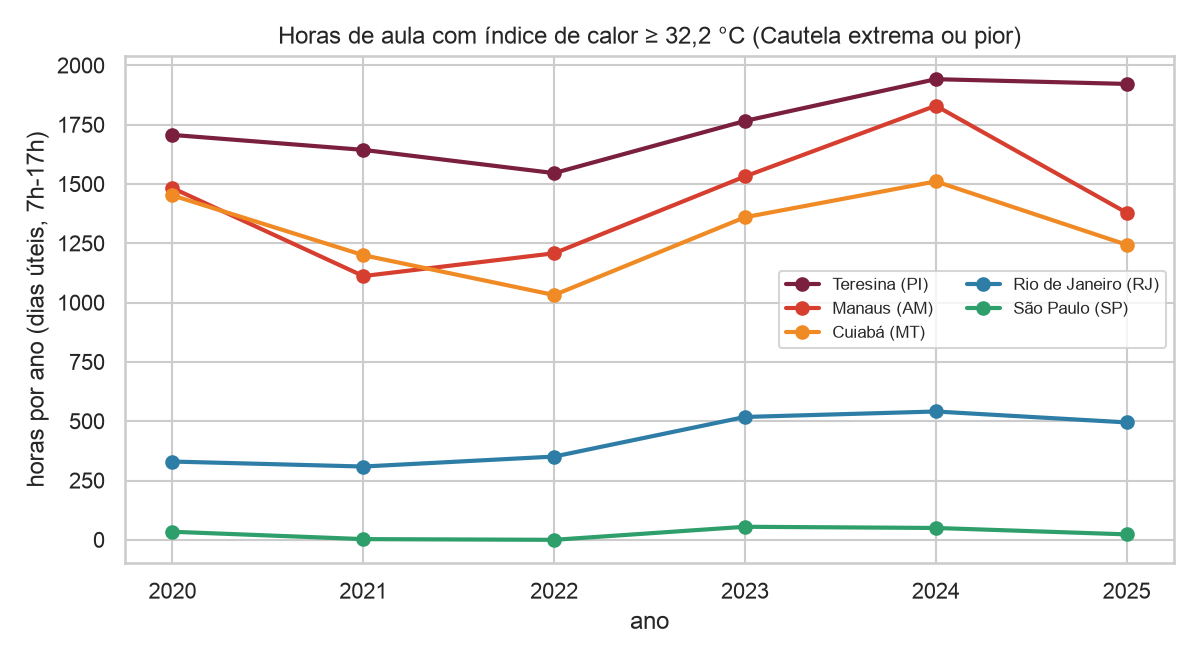

In [10]:
from IPython.display import Image
Image(str(config.DIR_FIGURAS / 'fig_horas_alerta_ano.png'))

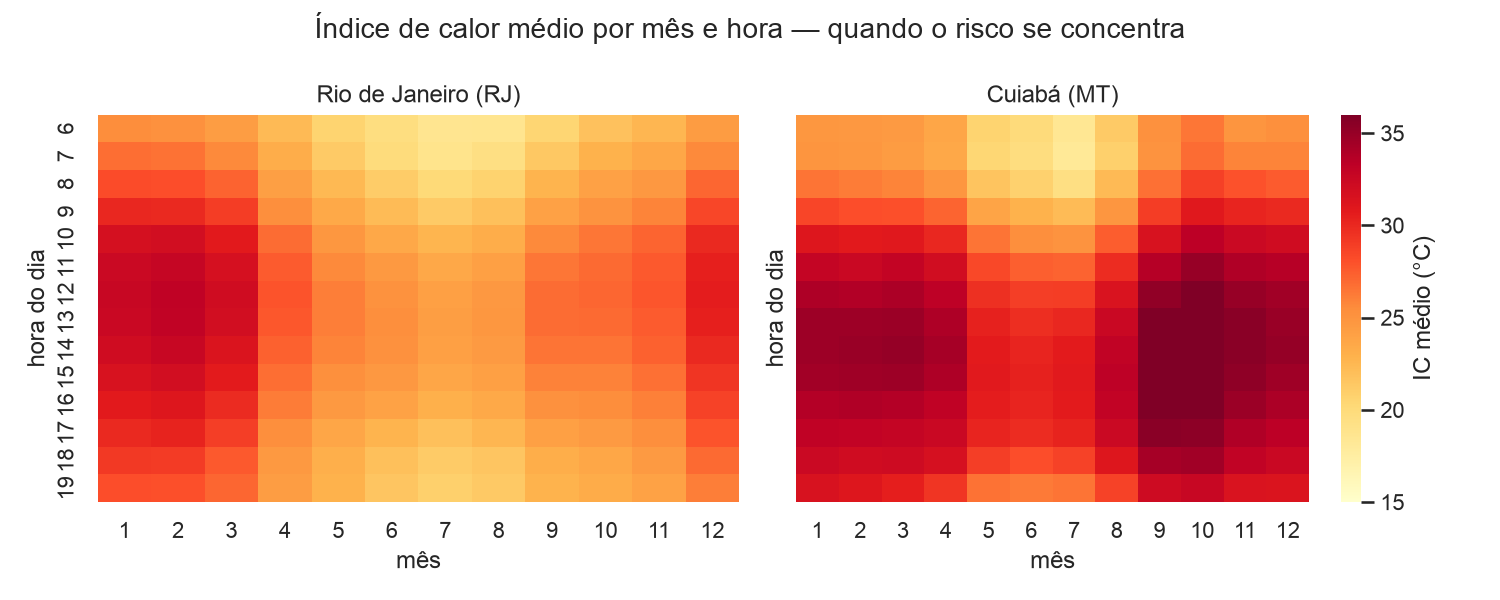

In [11]:
Image(str(config.DIR_FIGURAS / 'fig_mapa_mes_hora.png'))

### Teste de hipótese: o pico diário aumentou de 2020-2022 para 2023-2025?
Teste t de Welch (variâncias diferentes). **Cuidado:** são apenas 6 anos e 2023-2024 tiveram El Niño forte; o resultado descreve esse período e não prova tendência climática de longo prazo.

In [12]:
r['periodos']

,media_2020_2022,media_2023_2025,diferenca,t,p_valor
cidade,,,,,
Cuiabá (MT),34.14,35.11,0.97,4.78,1.900000e-06
Manaus (AM),34.07,35.24,1.18,9.86,2.700000e-22
Rio de Janeiro (RJ),28.18,29.56,1.38,5.19,2.400000e-07
São Paulo (SP),24.55,25.84,1.29,5.94,3.400000e-09
Teresina (PI),35.04,36.09,1.05,11.05,2.200000e-27


### Correlação entre variáveis

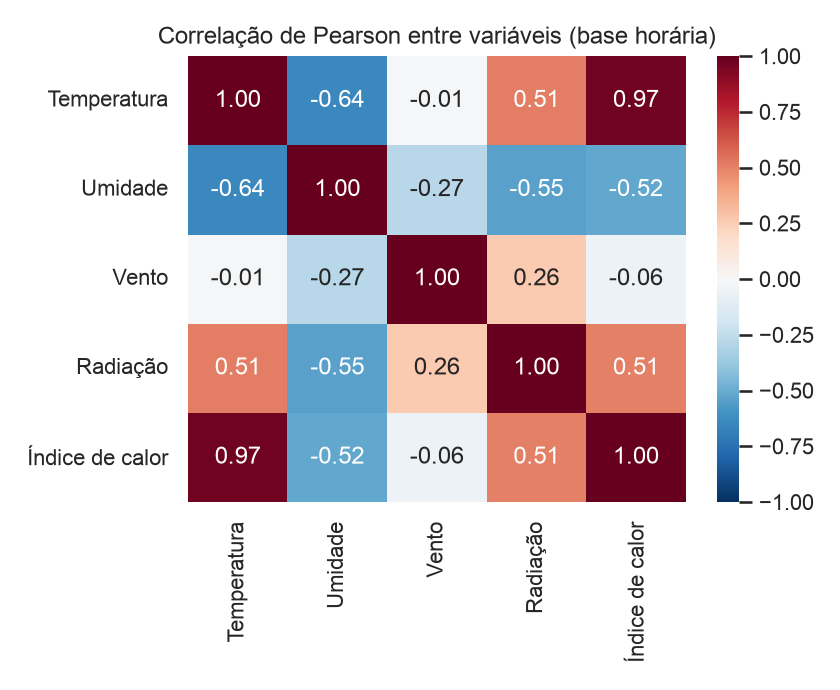

In [13]:
Image(str(config.DIR_FIGURAS / 'fig_correlacao.png'))

## 5. Machine Learning: previsão às 09h do pico da tarde
Uma linha por cidade e dia útil. Atributos: só o que se sabe até as 09h (e o pico de ontem). Divisão **temporal**: treino 2020-2023, teste 2024-2025.

In [14]:
diario = pd.read_csv(config.ARQ_DIARIO)
print(diario.shape)
diario[modelo.ATRIBUTOS + ['ic_max_tarde']].describe().round(2)

(7825, 15)


,temp_09h,umidade_09h,ic_09h,temp_06h,aquecimento_manha,radiacao_manha,vento_09h,ic_max_tarde_ontem,mes_sen,mes_cos,ic_max_tarde
count,7825.00,7825.0,7825.00,7825.00,7825.00,7825.00,7825.00,7825.00,7825.00,7825.00,7825.00
mean,25.06,73.7,26.35,21.77,3.28,577.49,8.59,31.74,-0.00,-0.00,31.73
std,4.09,14.1,5.12,3.99,1.94,338.72,4.97,5.59,0.71,0.71,5.61
min,6.00,19.0,4.41,1.40,-2.80,29.00,0.00,10.71,-1.00,-1.00,8.87
25%,23.00,66.0,23.36,19.50,1.80,299.00,4.80,27.77,-0.87,-0.87,27.74
50%,25.90,78.0,26.65,23.10,3.10,473.00,7.70,33.42,-0.00,-0.00,33.43
75%,27.70,84.0,30.22,24.60,4.60,830.00,11.50,35.98,0.50,0.87,35.94
max,36.20,100.0,39.36,30.00,12.10,1611.00,43.10,47.82,1.00,1.00,47.82


In [15]:
res = modelo.treinar_e_avaliar(diario)
pd.DataFrame(res['regressao'])

,modelo,MAE,RMSE,R2
0,Linha de base (pico de ontem),1.848,2.786,0.748
1,Regressão Linear,1.544,2.078,0.860
2,Random Forest,1.330,1.846,0.889


In [16]:
pd.DataFrame(res['classificacao'])

,modelo,acuracia,f1_macro,recall_cautela_extrema,recall_perigo
0,Linha de base (faixa de ontem),0.780,0.665,0.883,0.487
1,Regressão Logística,0.733,0.642,0.710,0.868
2,Árvore de Decisão,0.771,0.670,0.791,0.776
3,Random Forest,0.836,0.726,0.904,0.553


In [17]:
res['alerta_perigo']

{'limiar_probabilidade': 0.1,
 'escolhido_em': 'validação temporal 2021-2023 (maior recall com precisão >= 35%)',
 'recall_validacao': 0.861,
 'recall_teste': 0.868,
 'precisao_teste': 0.235,
 'dias_perigo_reais_teste': 76,
 'alertas_emitidos_teste': 281}

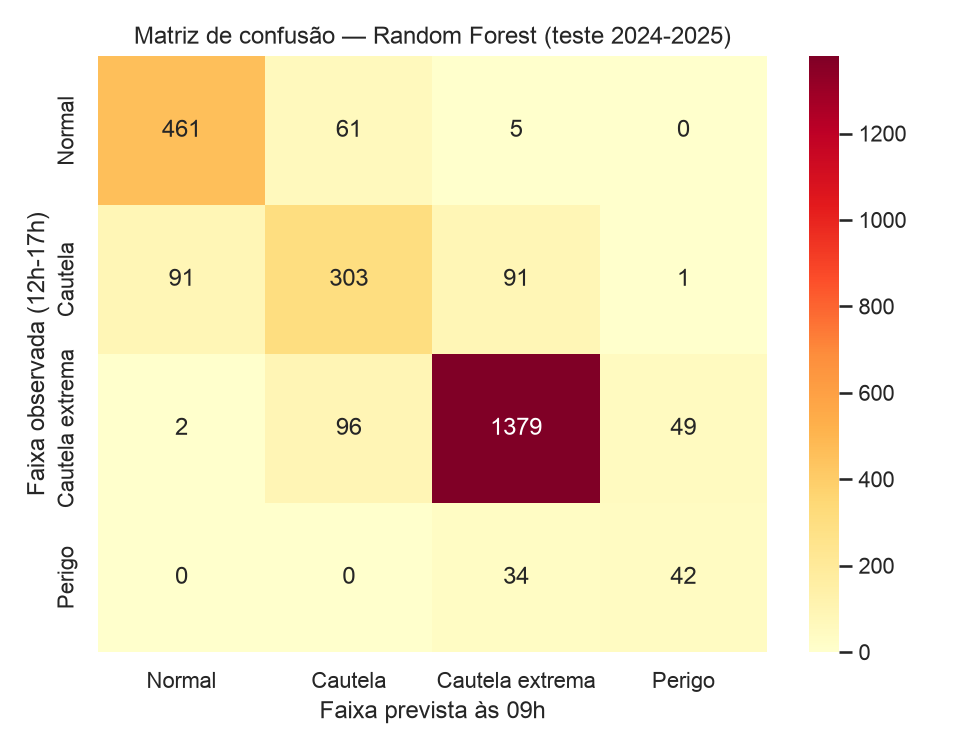

In [18]:
Image(str(config.DIR_FIGURAS / 'fig_matriz_confusao.png'))

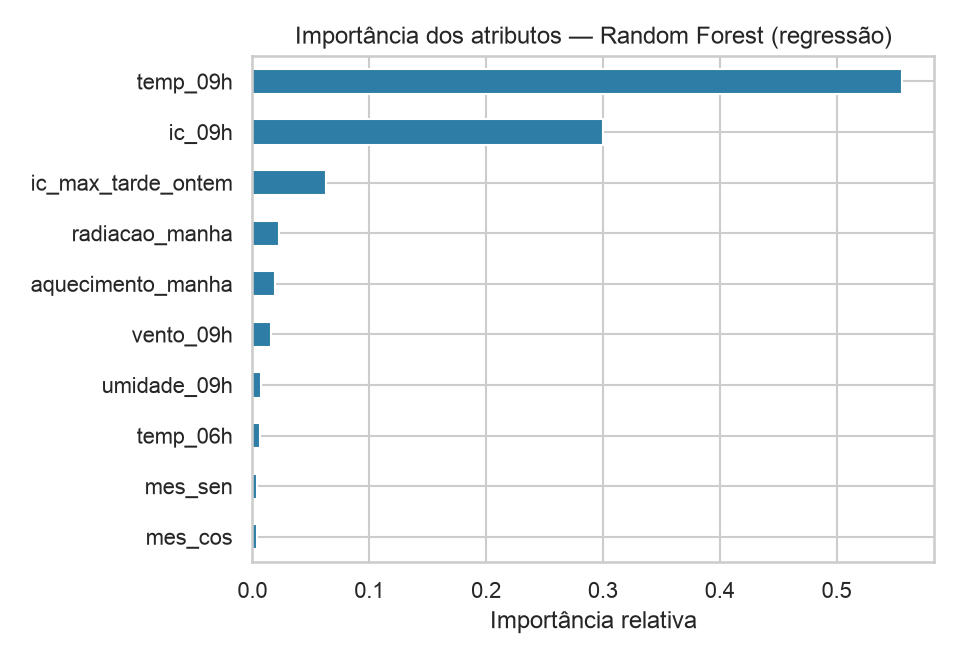

In [19]:
Image(str(config.DIR_FIGURAS / 'fig_importancia_atributos.png'))

## 6. Conclusões da análise
- O índice de calor em horário escolar passa de 32,2 °C em 61% das horas de aula em Teresina, 50% em Manaus, 45% em Cuiabá, 15% no Rio de Janeiro e 1% em São Paulo (dado externo, ERA5).
- O Random Forest reduz o erro do pico previsto em relação à linha de base de persistência (pico de ontem).
- O limiar extra para o aviso de *Perigo* aumenta o recall, mas emite mais alarmes falsos; essa troca está documentada no relatório.